In [280]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import seaborn as sns
import pandas as pd

In [281]:
np.random.seed(42)
dataset=np.loadtxt('ex1data1.txt',delimiter=',')
dataset[:5,:]
X=dataset[:,:-1]
y=dataset[:,-1]

print(f'shapes of X and Y {X.shape, y.shape}')



shapes of X and Y ((97, 1), (97,))


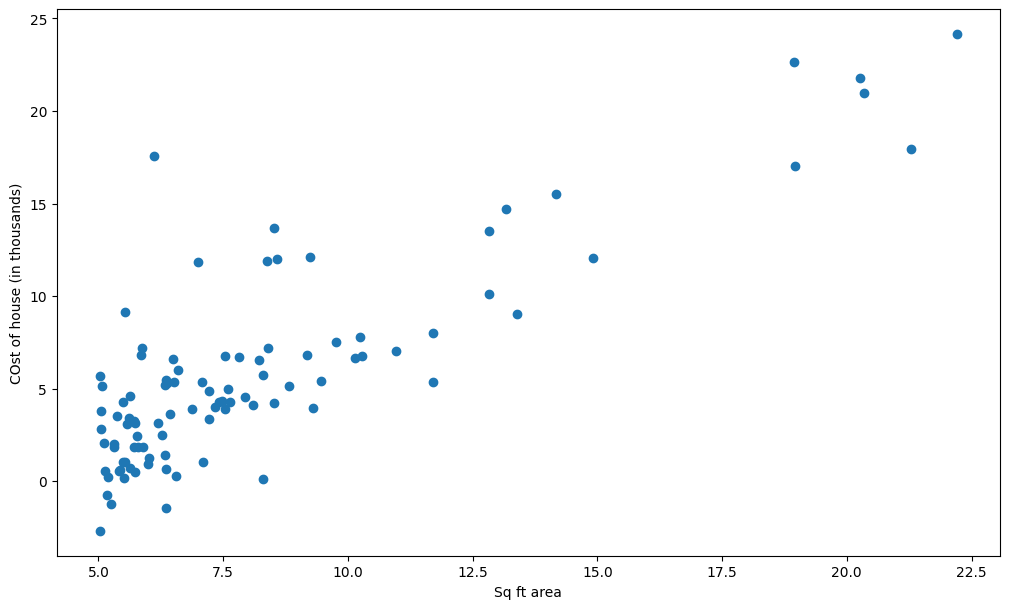

In [282]:
#plot data
if X.shape[1] is None or X.shape[1]==1:
    plt.figure(1,figsize=(10,6))
    plt.scatter(X,y,marker='o')
    plt.tight_layout()
    plt.ylabel('COst of house (in thousands)')
    plt.xlabel('Sq ft area')
else:
    sns.pairplot(pd.DataFrame(dataset))

In [283]:
#train test split
testSize=int(0.1*len(X))

idx=np.random.permutation(len(X))

train_idx=idx[testSize:]
test_idx=idx[:testSize]

X_train,X_test=X[train_idx],X[test_idx]
y_train,y_test=y[train_idx],y[test_idx]

In [284]:
def standardize_data(x): #can be skipped here as only 1 feature
    mean=np.mean(x,0) #if no axis then the mean of whole array 
    std=np.std(x,0,ddof=1)
    x_std=(x-mean)/std

    return x_std,mean,std
Xtrain_std,tr_mean,tr_std=standardize_data(X_train)
Xtest_std=(X_test-tr_mean)/tr_std
Xtrain_std.shape


(88, 1)

In [285]:
Xtrain_std_full=np.c_[np.ones(Xtrain_std.shape[0]),Xtrain_std]
Xtest_std_full=np.c_[np.ones(Xtest_std.shape[0]),Xtest_std]
Xtrain_std_full.shape

(88, 2)

In [286]:
Hessian=(1/Xtrain_std_full.shape[0])*(Xtrain_std_full.T @ Xtrain_std_full)
eigenValue=np.linalg.eigvals(Hessian)
print(2/eigenValue.max())
#theoretically optimal constant learning rate ($\eta_{\text{opt}}$) that minimizes the overall number of iterations
print(2/(eigenValue.max()+eigenValue.min()))


2.0
1.0057142857142856


In [287]:
def normalEquations(x,y):
     return np.linalg.inv(x.T @ x)@x.T @ y

theta_n=normalEquations(Xtrain_std_full,y_train)
Xtrain_std_full.shape
theta_n

array([5.78218773, 4.46992738])

In [288]:
def computeCost(x,y,theta):
    m=int(y.shape[0])
    residual=np.dot(x,theta)-y
    cost=(np.sum(residual**2))/(2*m)
    return cost

theta=np.zeros(Xtrain_std_full.shape[1])
initalCost=computeCost(Xtrain_std_full,y_train,theta)
cost_normalEqn=computeCost(Xtrain_std_full,y_train,theta_n)
initalCost,cost_normalEqn
theta_n

array([5.78218773, 4.46992738])

Best alpha: 0.03, Loss: 4.6321
Best theta: [5.78215816 4.46990107]
normal eqations theta: [5.78218773 4.46992738]


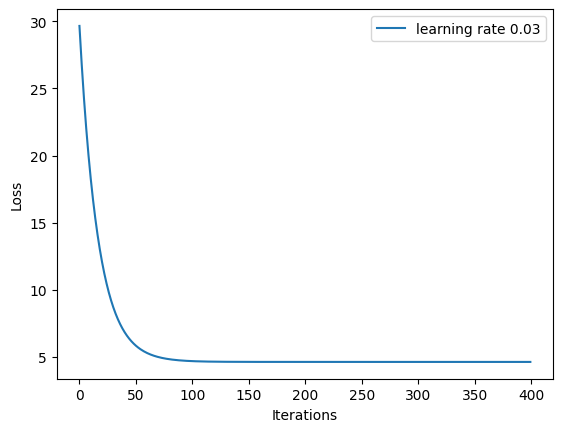

In [289]:
iterations=400
alpha=[0.03]#[0.03,0.01,0.001]

def GradientDescent(xtr,ytr,xtest,ytest,theta,alpha,iterations):
    trloss_list=[]
    teloss_list=[]
    theta_history=[theta.copy()]

    m=int(ytr.size)
    for i in range(iterations):
        residual=np.dot(xtr,theta)-ytr
        grad=(1/m)*np.dot(xtr.T,residual)
        theta -= alpha * (grad)
        theta_history.append(theta.copy()) 
        trloss=computeCost(xtr,ytr,theta)
        teloss=computeCost(xtest,ytest,theta)
        trloss_list.append(trloss)
        teloss_list.append(teloss)
    return theta, trloss_list,teloss_list,np.array(theta_history)
best_alpha=None
best_theta=None
best_loss=np.inf

#gridsearch for alpha
for i in alpha:
    theta=np.zeros(Xtrain_std_full.shape[1])
    theta_gd,loss,test_loss,theta_history=GradientDescent(Xtrain_std_full,y_train,Xtest_std_full,y_test,theta,i,iterations)
    plt.plot(range(iterations),loss,label=f'learning rate {i}')
    final_loss=loss[-1]
    if np.isfinite(final_loss) and final_loss<best_loss:
        best_alpha=i
        best_theta=theta_gd
        best_loss=final_loss
print(f"Best alpha: {best_alpha}, Loss: {best_loss:.4f}")
print(f"Best theta: {best_theta}")
print(f'normal eqations theta: {theta_n}')

plt.xlabel('Iterations')
plt.ylabel('Loss')
plt.legend()



# theta_gd,loss[-1]

        

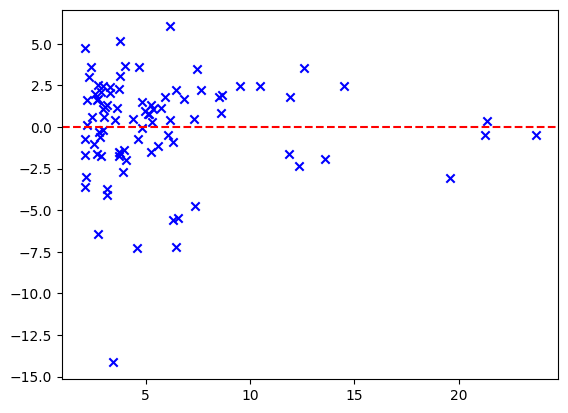

In [290]:
predictions=np.dot(Xtrain_std_full,theta_gd)
train_residuals=predictions-y_train
plt.scatter(predictions,train_residuals,marker='x',c='b')
plt.axhline(y=0,color='red',linestyle='--')


normalEqn theta:[5.78218773 4.46992738] 
gdTheta:[5.78215816 4.46990107]
trainloss:4.6321
testloss:3.4716



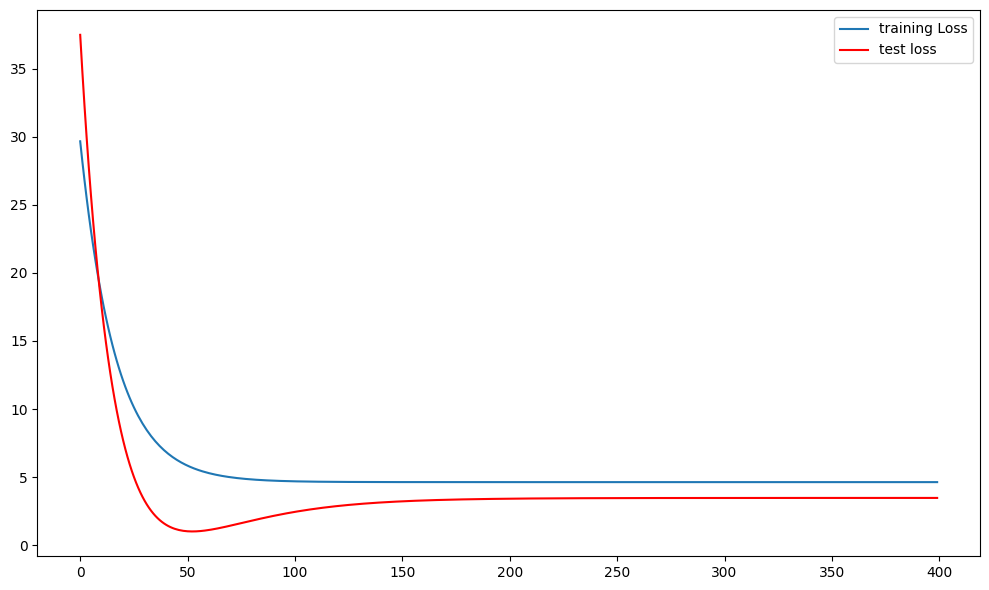

In [291]:
plt.figure(figsize=(10,6))
plt.plot(range(iterations),loss,label='training Loss')
plt.plot(range(iterations),test_loss,c='r',label='test loss')
plt.tight_layout()
plt.legend()
print(f'normalEqn theta:{theta_n} \n'
      f'gdTheta:{theta_gd}\n'
      f'trainloss:{loss[-1]:.4f}\n'
      f'testloss:{test_loss[-1]:.4f}\n'
      )


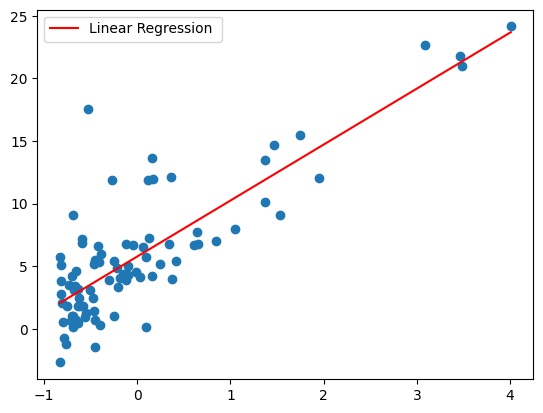

In [292]:
plt.figure(1)
#since data is randomly shuffled
plt.scatter(Xtrain_std_full[:,1],y_train,marker='o')
sorted_idx=np.argsort(Xtrain_std_full[:,1])
line,=plt.plot(Xtrain_std_full[sorted_idx,1],predictions[sorted_idx],c='r',label='Linear Regression ')
plt.legend(handles=[line])

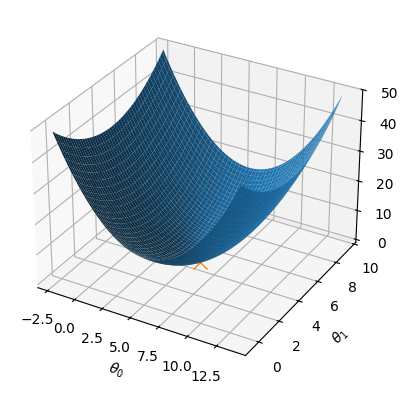

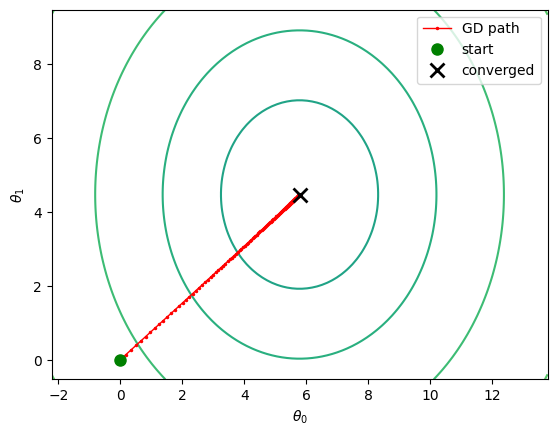

In [293]:
theta1_values = np.linspace(theta_gd[1]-5, theta_gd[1]+5, 100)
thet0_values  = np.linspace(theta_gd[0]-8, theta_gd[0]+8, 100)

xs,ys=np.meshgrid(thet0_values,theta1_values)
loss_values=np.zeros(xs.shape)
loss_values = np.array([[computeCost(Xtrain_std_full, y_train, np.array([t0, t1]))
                         for t0 in thet0_values] for t1 in theta1_values])

fig=plt.figure()
ax=fig.add_subplot(111,projection='3d')
ax.plot_surface(xs, ys, loss_values)
plt.plot(theta_gd[0],theta_gd[1],marker='x',markersize=10)
plt.xlabel(r'$\theta_0$')
plt.ylabel(r'$\theta_1$')

#contour plot
plt.figure()
lvls=np.logspace(-2,3,20)
plt.contour(xs,ys,loss_values,levels=lvls,norm=LogNorm())

#GDPath
theta_history_1=theta_history[::20] #to decongest the path sample 20 
plt.plot(theta_history[:,0], theta_history[:,1], 'r.-', markersize=3, linewidth=1, label='GD path')
plt.plot(theta_history[0,0], theta_history[0,1], 'go', markersize=8, label='start')
plt.plot(theta_gd[0], theta_gd[1], 'kx', markersize=10, mew=2, label='converged')

plt.xlabel(r'$\theta_0$')
plt.ylabel(r'$\theta_1$')
plt.legend()


